# Outpatient–Nursing Pressure and U.S. Hospital Employment

# Outpatient–Nursing Pressure → U.S. Hospital Employment (NAICS 622)

**Status: REPRODUCED RETROSPECTIVE HOSPITAL-EMPLOYMENT MACRO FALSIFICATION · NOT VERIFIED PIT · NOT EQUITY ALPHA.**  
**Data freeze:** 2026-10-26 inherited official BLS/FRED revised snapshot; research 2026-10-28. **Independent outcome:** U.S. hospital payroll employment, *not* admissions, corporate sales or total equity returns.

**Computational record:** the following code cells load the frozen data, independently calculate features and forecasts, rerun all 1,000/2,000-draw falsification tests, and display the resulting tables and figures. No PIT/equity alpha claim is made.

## 01. Abstract
**Question:** Does two-month-stale outpatient-care hiring growth relative to nursing/residential-care hiring improve six-month-ahead U.S. **hospital** payroll growth forecasts after hospital persistence and economy-wide hiring are controlled? A frozen **201-month** official BLS CES panel (2010-01–2026-09) provides **99 purged expanding-window forecasts** (2018-01–2026-03). Adding the factor reduces macro-control OOS RMSE from **4.5501** to **4.2742 log percentage points**, but is **far worse than hospital persistence (1.4184) and historical mean (1.7681)**; gains disappear outside 2020–2021. The 1,000-block-reorder exploratory tail fraction is **0.2248**, and the 2,000-draw paired moving-block gain interval **[-0.1782, +0.5870]** crosses zero. **Verdict:** a reproducible, pandemic-sensitive, *negative* hospital-sector macro-factor pilot, not a point-in-time or investable equity-alpha result.

In [1]:
from pathlib import Path
import json, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import run_analysis as ra
ROOT=Path.cwd(); print('Notebook working directory:', ROOT)

Notebook working directory: /mnt/data/s2a_hospital_20261028/study


In [2]:
m0=json.loads((ROOT/'results/metrics.json').read_text()); print('Research status:',m0['status']); print('OOS origins:',m0['oos_origins']); print('Historical vintages:',m0['historical_publication_vintages'])

Research status: REPRODUCED RETROSPECTIVE HOSPITAL-EMPLOYMENT MACRO FALSIFICATION — NOT PIT / NOT EQUITY ALPHA
OOS origins: 99
Historical vintages: UNKNOWN — NOT PIT


## 02. Research Design & Hypotheses
**H1 (mechanism):** faster growth in ambulatory care *excluding home health* than in nursing/residential care may lead hospital referrals, diagnostic utilization and eventual hospital staffing demand. **H2 (incremental):** this fixed relative-growth score should improve six-month-ahead hospital hiring forecasts beyond hospital own-growth, national payroll and nursing growth. **H3 (robustness):** any gain should persist across pre/post-pandemic regimes, longer data-release buffers, 3/9-month horizons, rolling fits and block-aware nulls. **Null:** no incremental predictive value after controls. **Counterthesis:** outpatient substitution may *reduce* hospital demand, hospital payroll reflects staffing shortages/reimbursement rather than visits, and COVID caused correlated labor disruptions. A primary failure condition is **not beating the best simple baseline**, regardless of improvements against an overfitted multivariate control.

In [3]:
print('H1: referral/transmission; H2: OOS gain; H3: regime and lag robustness')
print('Null: no incremental information. Failure gate: beat strongest simple baseline.')

H1: referral/transmission; H2: OOS gain; H3: regime and lag robustness
Null: no incremental information. Failure gate: beat strongest simple baseline.


In [4]:
assert ra.ALPHA==10 and ra.START_OOS==pd.Timestamp('2018-01-01'); print('Fixed alpha and OOS start:',ra.ALPHA,ra.START_OOS.date())

Fixed alpha and OOS start: 10.0 2018-01-01


## 03. Industry Context
The target is **NAICS 622 Hospitals**, distinct from the prior nursing/residential-care outcome **NAICS 623**. September 2026 BLS CES payrolls in this fixed snapshot are **5,797.8 thousand** hospital workers, **9,266.4 thousand** ambulatory workers, **1,894.2 thousand** home-health workers and **3,489.4 thousand** nursing/residential workers. These are **employment levels, not industry revenues or patient volumes**. Ambulatory services (NAICS 621) include home-health care (6216), so subtracting the nested home-health series is necessary before claiming an outpatient *nonhome* proxy; this arithmetic difference remains a rough labor proxy, not patient flows. Source pages and 2026-10-02 release are in the register. The economic channel is ambiguous because referrals and substitution can operate in opposite directions.

In [5]:
raw=ra.load_raw(); display(raw.tail(5))

,date,home,hospital,nursing,ambulatory,payroll
196,2026-05-01,1878.0,5761.3,3490.1,9224.8,158861.0
197,2026-06-01,1881.2,5771.3,3496.0,9227.3,158892.0
198,2026-07-01,1884.7,5774.4,3496.3,9241.8,158882.0
199,2026-08-01,1896.5,5785.8,3498.1,9253.0,159015.0
200,2026-09-01,1894.2,5797.8,3489.4,9266.4,159044.0


In [6]:
display(pd.DataFrame({'segment':['Hospitals','Ambulatory','Home health','Nursing'], 'Sep_2026_thousand':[raw[c].iloc[-1] for c in ['hospital','ambulatory','home','nursing']]}))

,segment,Sep_2026_thousand
0,Hospitals,5797.8
1,Ambulatory,9266.4
2,Home health,1894.2
3,Nursing,3489.4


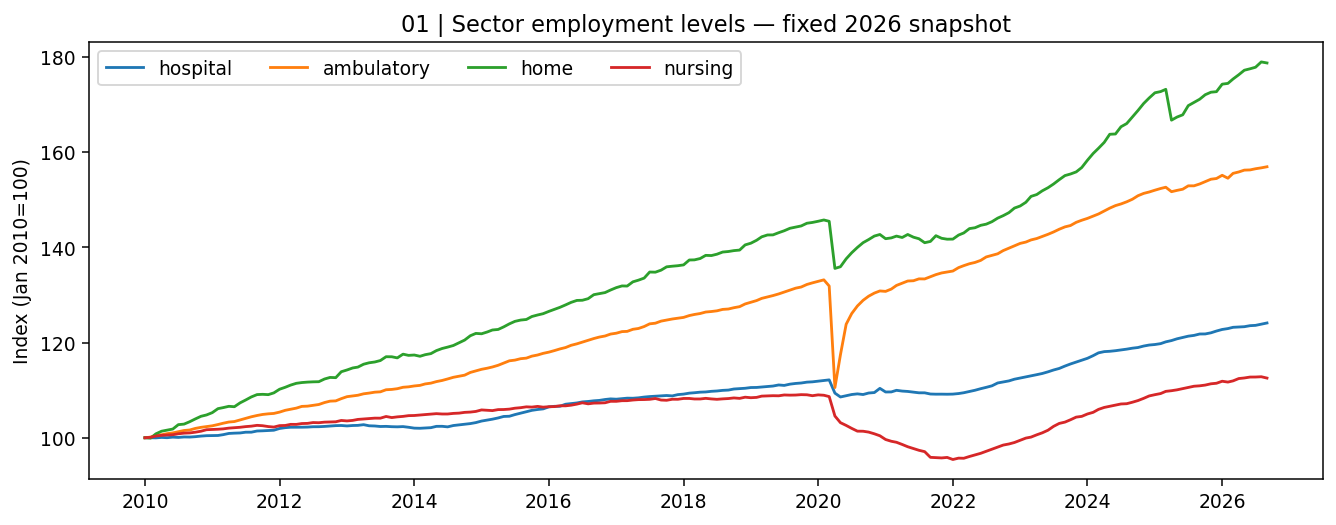

In [7]:
display(Image(filename=str(ROOT/'figures/01_sector_levels.png')))

## 04. Data & Source Integrity
Five seasonally adjusted BLS Current Employment Statistics series were frozen in the previous Signals-to-Alpha healthcare study on **2026-10-26**. The file `data/raw_fred_ces_2010_2026_snapshot.csv` is **byte-identical** to that source (**SHA-256 `f1d5a8ff28a55f2d1798cbdb9cac239d46db6c006b0a9e1801abae1b3b1665f6`**), reconstructed and verified without new web retrieval; it is **not** a fresh independently downloaded 2026-10-28 vintage. Observations: **201 monthly rows**, January 2010–September 2026; no missing/duplicate dates, all employment counts positive, and ambulatory minus home health strictly positive. The source register records publisher, original FRED/BLS URL, download URL, grade A/B/C, units, observed dates, collection date, latest release, historical vintage **UNKNOWN**, revision risk and usage. A/B/C distinguishes original government series, inherited snapshot and analyst scenario weights; grade A does **not** establish PIT availability. SEC 2025 10-K sources are descriptive issuer maps only.

In [8]:
source=pd.read_csv(ROOT/'data/source_register.csv'); display(source[['source_id','grade','publisher','collection_date','source_release_date','historical_vintage']])

,source_id,grade,publisher,collection_date,source_release_date,historical_vintage
0,CES6562200001,A,U.S. Bureau of Labor Statistics via FRED,2026-10-26,2026-10-02,latest revised snapshot not PIT
1,CES6562100001,A,U.S. Bureau of Labor Statistics via FRED,2026-10-26,2026-10-02,latest revised snapshot not PIT
2,CES6562160001,A,U.S. Bureau of Labor Statistics via FRED,2026-10-26,2026-10-02,latest revised snapshot not PIT
3,CES6562300001,A,U.S. Bureau of Labor Statistics via FRED,2026-10-26,2026-10-02,latest revised snapshot not PIT
4,PAYEMS,A,U.S. Bureau of Labor Statistics via FRED,2026-10-26,2026-10-02,latest revised snapshot not PIT
5,HCA_2025_10K,A,U.S. Securities and Exchange Commission,2026-10-28,2026-02-10,filing-date verified descriptive only
6,THC_2025_10K,A,U.S. Securities and Exchange Commission,2026-10-28,2026-02-17,filing-date verified descriptive only
7,SNAPSHOT_INHERITANCE,B,Signals-to-Alpha prior study,2026-10-28,2026-10-26,byte-identical SHA256 to inherited snapshot
8,WEIGHT_PRIOR,C,Analyst fixed scenario prior,2026-10-28,2026-10-28,not applicable


In [9]:
assert hashlib.sha256(ra.RAW.read_bytes()).hexdigest()==ra.EXPECTED_SHA; print('SHA256:',ra.EXPECTED_SHA,'rows:',len(raw),'missing:',int(raw.isna().sum().sum()))

SHA256: f1d5a8ff28a55f2d1798cbdb9cac239d46db6c006b0a9e1801abae1b3b1665f6 rows: 201 missing: 0


In [10]:
assert raw.date.is_unique and (raw.ambulatory>raw.home).all(); print('Monthly dates and nonhome subtraction: PASS')

Monthly dates and nonhome subtraction: PASS


## 05. Point-in-Time Availability
At formation month **t**, every candidate input is measured at **t−2** or earlier, a conservative assumed two-month delay for monthly payroll data. For each expanding-window training example **u**, its six-month-forward YoY target must mature by **u+6+1 ≤ t**, including a one-month assumed target-release buffer; no model sees a future target. All model centering and scaling are fitted **within each training fold**; ridge penalty **α=10** and signal scale **5 log-pp** are fixed. This is **not verified PIT**: 2026-10-26 CES revisions are embedded throughout 2010–2026, and neither original observation-specific release timestamps nor ALFRED first-release vintages have been reconstructed. Release-buffer assumptions cannot repair revision leakage.

In [11]:
p=ra.make_panel(raw); o=ra.walk_forward(p); display(p[['date','t','target_mature_t','factor','target']].head())

,date,t,target_mature_t,factor,target
0,2011-03-01,14,21,0.033106,1.259508
1,2011-04-01,15,22,0.032711,1.222660
2,2011-05-01,16,23,0.068564,1.166355
3,2011-06-01,17,24,0.118672,1.133787
4,2011-07-01,18,25,0.094647,1.467877


In [12]:
for row in o.iloc[[0,-1]].itertuples():
 tr=p.loc[p.target_mature_t<=row.t]
 print(row.date.date(),'training n=',len(tr),'last matured index=',int(tr.target_mature_t.max()),'formation index=',row.t)
 assert (tr.target_mature_t<=row.t).all()

2018-01-01 training n= 76 last matured index= 96 formation index= 96
2026-03-01 training n= 174 last matured index= 194 formation index= 194


In [13]:
print('Fixed two-month feature buffer; target maturity +7 months; historical vintage UNKNOWN.')

Fixed two-month feature buffer; target maturity +7 months; historical vintage UNKNOWN.


## 06. Factor Construction
Let H=hospital payroll, A=all ambulatory payroll, C=home-health payroll, N=nursing/residential payroll and P=total nonfarm payroll; all are seasonally adjusted thousands. Define **O=A−C**, a strictly positive outpatient-nonhome labor proxy. For any series X, at formation month **t** use `g_X(t)=100 ln[X(t−2)/X(t−14)]`. The *predeclared fixed* factor is `F(t)=tanh((g_O(t)−g_N(t))/5)`, with **5 log-pp** a saturation scale selected without fitting outcomes. Controls are `g_H(t)`, `g_P(t)` and `g_N(t)`; `g_N` also appears in the factor, so multicollinearity is a known limitation. The independent target is `Y(t)=100 ln[H(t+6)/H(t−6)]` (future six-month-ahead **YoY** hospital employment growth, **not** a six-month growth rate). Lagged hospital six-month momentum is a separate baseline. No full-sample z-score or return-optimized weights are used.

In [14]:
display(p[['date','g_outpatient_nonhome','g_nursing','factor','target']].iloc[::24].head(10))

,date,g_outpatient_nonhome,g_nursing,factor,target
0,2011-03-01,1.888970,1.723381,0.033106,1.259508
24,2013-03-01,2.894967,0.960869,0.368615,-0.056467
48,2015-03-01,2.957400,1.112195,0.353153,2.653166
72,2017-03-01,3.185423,1.057095,0.401693,0.958799
96,2019-03-01,2.324335,0.142895,0.410563,1.258705
120,2021-03-01,-1.365672,-8.989881,0.909538,0.098070
144,2023-03-01,4.071258,4.143819,-0.014511,3.137008
168,2025-03-01,2.834916,3.788366,-0.188412,2.476951


In [15]:
r=p.iloc[30];assert np.isclose(r.factor,np.tanh((r.g_outpatient_nonhome-r.g_nursing)/5)); print('Factor equation independently checked at',r.date.date())

Factor equation independently checked at 2013-09-01


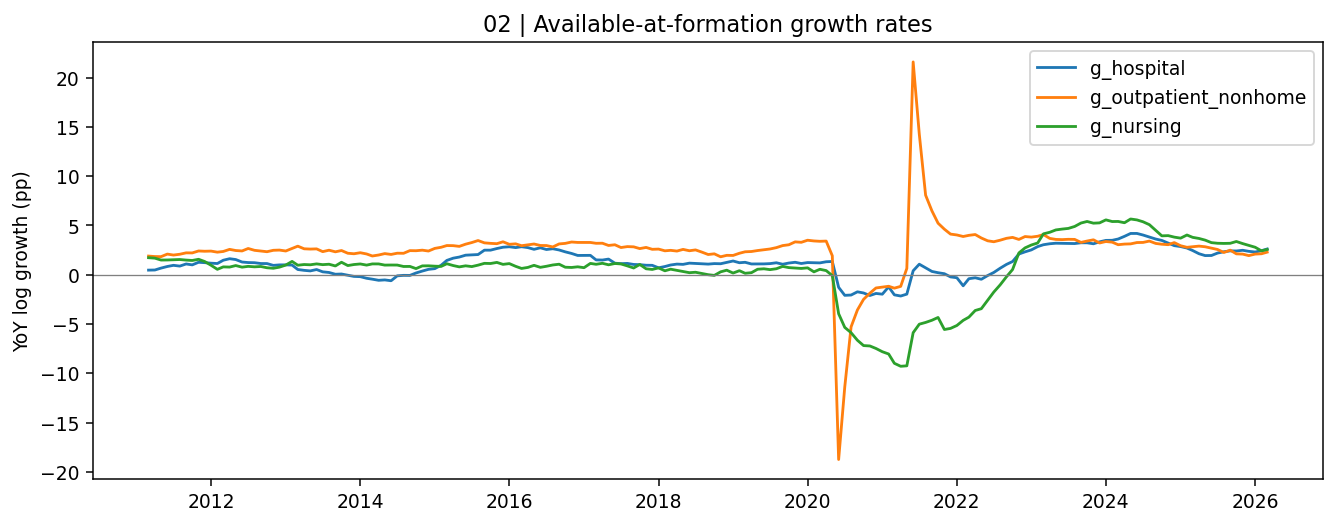

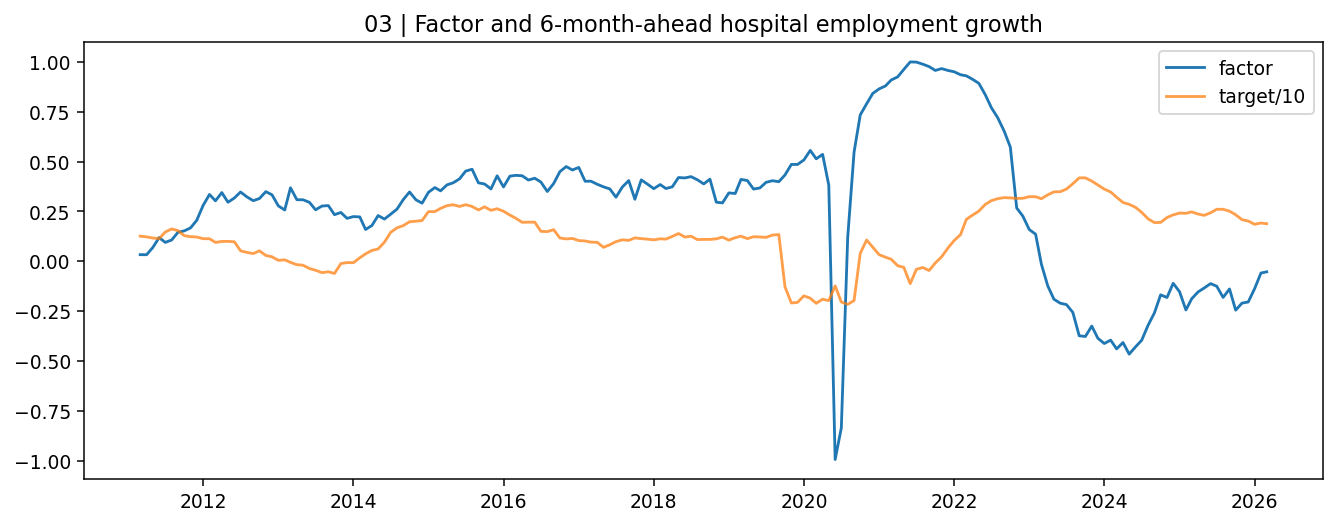

In [16]:
display(Image(filename=str(ROOT/'figures/02_growth_rates.png')));display(Image(filename=str(ROOT/'figures/03_factor_target.png')))

## 07. Exposure & Transmission
`data/sector_exposure_map.csv` maps NAICS 621 (ambulatory, positive), 6216 (home health, excluded from positive leg), 623 (nursing, negative leg/control) and 622 (hospital outcome), all as of the 2026-10-26 frozen CES snapshot. **Issuer exposure is descriptive only**: the 2025 SEC filings dated **2026-02-10** (HCA Healthcare) and **2026-02-17** (Tenet Healthcare) establish that HCA operated 190 hospitals and 121 freestanding ambulatory surgery centers, while Tenet reported 50 hospitals and a separate ambulatory segment with interests in 533 ASCs; segment accounting does not map one-to-one to CES payroll. Their **historical revenue exposure weights are UNKNOWN**, not backfilled to 2010; no issuer is a model observation. HCA's reported 2024/2025 consolidated revenue **$70.603B/$75.600B** is stored in `data/issuer_fundamentals_descriptive.csv` only to demonstrate a dated actual fundamental, **not** an OOS revenue forecast. Consequently leave-one-company-out and security IC/spreads are **not applicable**; leave-one-*calendar-year*-out is the available macro stability test.

In [17]:
display(pd.read_csv(ROOT/'data/sector_exposure_map.csv'))

,segment,naics,series,role,fixed_weight,weight_sensitivity_range,asof,source_url
0,Hospitals,622,CES6562200001,independent employment outcome,0.0,not applicable,2026-10-26,https://fred.stlouisfed.org/series/CES6562200001
1,Ambulatory care excluding home health,621 minus 6216,CES6562100001 minus CES6562160001,primary candidate upstream demand proxy,1.0,0.5 to 1.0,2026-10-26,https://fred.stlouisfed.org/series/CES6562100001
2,Home health care services,6216,CES6562160001,alternative candidate upstream proxy,0.0,0.0 to 0.5,2026-10-26,https://fred.stlouisfed.org/series/CES6562160001
3,Nursing and residential care,623,CES6562300001,negative factor leg and control,-1.0,fixed,2026-10-26,https://fred.stlouisfed.org/series/CES6562300001
4,Total nonfarm payrolls,all,PAYEMS,macro control,0.0,not applicable,2026-10-26,https://fred.stlouisfed.org/series/PAYEMS


In [18]:
display(pd.read_csv(ROOT/'data/issuer_exposure_map.csv')[['issuer','ticker','filing_date','reported_facilities','historical_revenue_weight','backtest_use']])

,issuer,ticker,filing_date,reported_facilities,historical_revenue_weight,backtest_use
0,HCA Healthcare,HCA,2026-02-10,190 hospitals,UNKNOWN,NO
1,Tenet Healthcare,THC,2026-02-17,50 acute and specialty hospitals,UNKNOWN,NO


In [19]:
display(pd.read_csv(ROOT/'data/issuer_fundamentals_descriptive.csv'));print('Issuer revenue observations are descriptive, not an OOS panel.')

,issuer,fiscal_year,consolidated_revenue_usd_billions,filing_date,source_url,role
0,HCA Healthcare,2024,70.603,2026-02-10,https://www.sec.gov/Archives/edgar/data/860730...,descriptive contemporaneous filing not backtest
1,HCA Healthcare,2025,75.600,2026-02-10,https://www.sec.gov/Archives/edgar/data/860730...,descriptive contemporaneous filing not backtest


Issuer revenue observations are descriptive, not an OOS panel.


## 08. Outcomes & Baselines
The sole predictive outcome is future **hospital payroll YoY log growth**. **99 common monthly origins** from 2018-01-01 through 2026-03-01 use expanding training with ≥60 matured observations. Comparators: (1) expanding historical mean, (2) hospital-growth persistence ridge, (3) hospital six-month momentum ridge, (4) hospital growth + momentum AR Ridge, (5) macro controls (hospital + total payroll + nursing growth), (6) the identical controls + factor, (7) factor-only, plus no-nursing/no-payroll ablations. Ridge α=10 is fixed, standardization is train-only, and forecasts share the exact same origins. Report RMSE/MAE in log-pp and paired losses. A **temporal Spearman rank association** is not a cross-sectional equity Rank IC. No issuer total returns, benchmark-adjusted returns, long-short spread, Sharpe or costs are computed.

In [20]:
print('Common OOS origins:',len(o),'first:',o.date.iloc[0].date(),'last:',o.date.iloc[-1].date());display(o[['date','train_n','target','mean','persistence','macro_controls','full']].head())

Common OOS origins: 99 first: 2018-01-01 last: 2026-03-01


,date,train_n,target,mean,persistence,macro_controls,full
0,2018-01-01,76,1.073846,1.192527,0.949697,0.377535,0.297782
1,2018-02-01,77,1.125730,1.189809,1.012866,0.061708,0.027115
2,2018-03-01,78,1.111318,1.188329,1.091058,0.206304,0.164683
3,2018-04-01,79,1.246572,1.186551,1.136797,0.330403,0.345294
4,2018-05-01,80,1.389250,1.186358,1.123890,0.314995,0.295487


In [21]:
sc=ra.scorecard(o);display(sc.sort_values('rmse_log_pp'))

,model,n,rmse_log_pp,mae_log_pp
1,persistence,99,1.418448,1.050613
2,momentum,99,1.467012,1.060428
3,ar_ridge,99,1.493323,1.069074
0,mean,99,1.768064,1.399889
6,factor_only,99,1.795521,1.346556
8,no_payroll,99,1.895487,1.364574
5,full,99,4.274216,2.317342
4,macro_controls,99,4.550098,2.337231
7,no_nursing,99,4.742687,2.364787


In [22]:
assert (o.train_n>=60).all();assert o.date.is_unique;print('Training purge, common origins and minimum sample: PASS')

Training purge, common origins and minimum sample: PASS


## 09. Empirical Findings
| Model | OOS n | RMSE (log-pp) | MAE (log-pp) |
|:--|--:|--:|--:|
| mean | 99 | 1.7681 | 1.3999 |
| persistence | 99 | 1.4184 | 1.0506 |
| momentum | 99 | 1.4670 | 1.0604 |
| ar_ridge | 99 | 1.4933 | 1.0691 |
| macro_controls | 99 | 4.5501 | 2.3372 |
| full | 99 | 4.2742 | 2.3173 |
| factor_only | 99 | 1.7955 | 1.3466 |
| no_nursing | 99 | 4.7427 | 2.3648 |
| no_payroll | 99 | 1.8955 | 1.3646 |

The augmented model's **+0.2759 log-pp** RMSE improvement over a poor multivariate control does **not** constitute useful forecast alpha: hospital persistence is **1.4184** and historical mean **1.7681**, both dramatically better. The full model's residual performance is disproportionately harmed by COVID-era joint movements; the pre-2020 improvement is small and the post-2021 improvement is negative. Effective OOS squared-loss difference sample size under a 12-lag autocorrelation heuristic is **33.8**, not 99 independent observations. The entire 99-origin forecast panel and scorecard are saved in `results/` and Figures 01–07 display actual computed levels, growth, factor, forecasts and paired errors.

In [23]:
metrics=ra.run(draws=1000,boot_draws=2000,weight_draws=1000,figures=True);display(pd.Series(metrics).to_frame('computed'))

,computed
status,REPRODUCED RETROSPECTIVE HOSPITAL-EMPLOYMENT M...
raw_rows,201
panel_rows,181
oos_origins,99
first_oos,2018-01-01
last_oos,2026-03-01
raw_sha256,f1d5a8ff28a55f2d1798cbdb9cac239d46db6c006b0a9e...
lag_months,2
horizon_months,6
target_release_buffer_months,1


In [24]:
sc=pd.read_csv(ROOT/'results/scorecard.csv');display(sc.sort_values('rmse_log_pp'))

,model,n,rmse_log_pp,mae_log_pp
1,persistence,99,1.418448,1.050613
2,momentum,99,1.467012,1.060428
3,ar_ridge,99,1.493323,1.069074
0,mean,99,1.768064,1.399889
6,factor_only,99,1.795521,1.346556
8,no_payroll,99,1.895487,1.364574
5,full,99,4.274216,2.317342
4,macro_controls,99,4.550098,2.337231
7,no_nursing,99,4.742687,2.364787


In [25]:
print('Macro-control improvement:',metrics['gain_log_pp'],'but persistence RMSE:',metrics['persistence_rmse']);assert metrics['persistence_rmse']<metrics['full_rmse']

Macro-control improvement: 0.2758820672454618 but persistence RMSE: 1.418447680245777


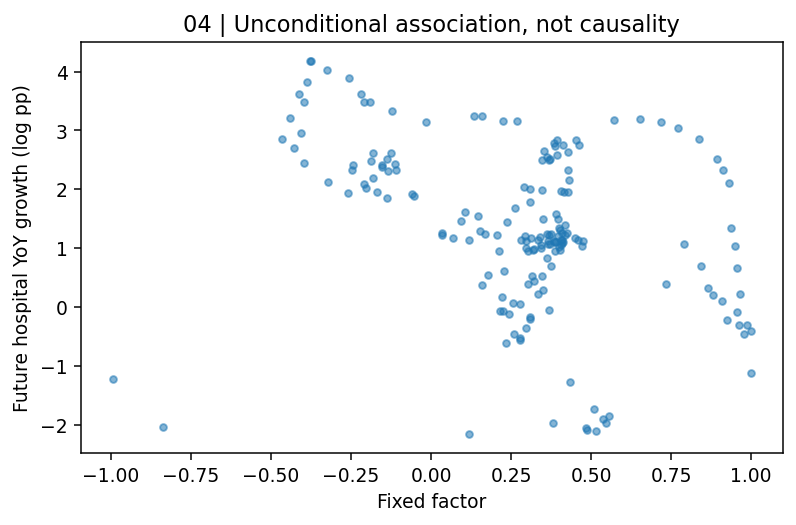

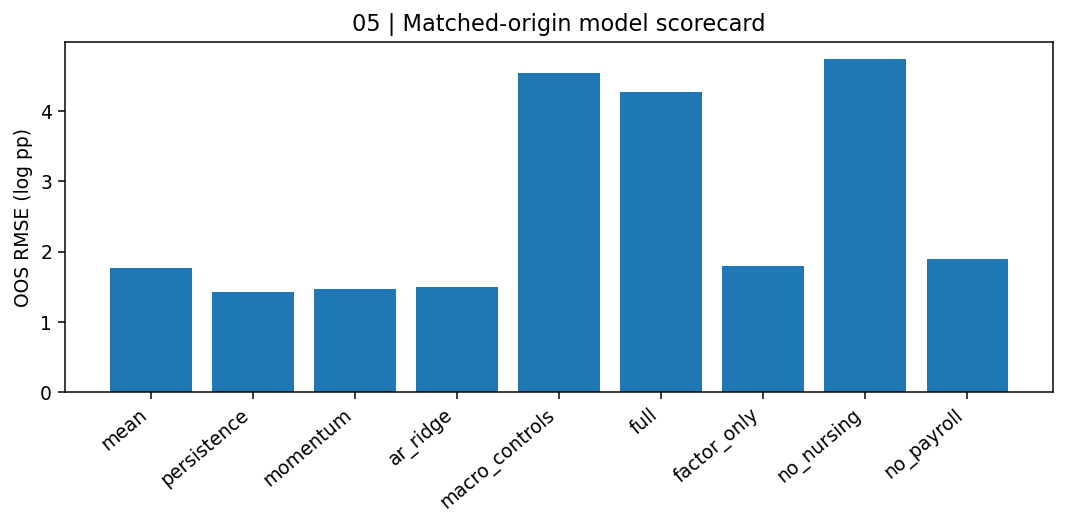

In [26]:
display(Image(filename=str(ROOT/'figures/04_scatter.png')));display(Image(filename=str(ROOT/'figures/05_scorecard.png')))

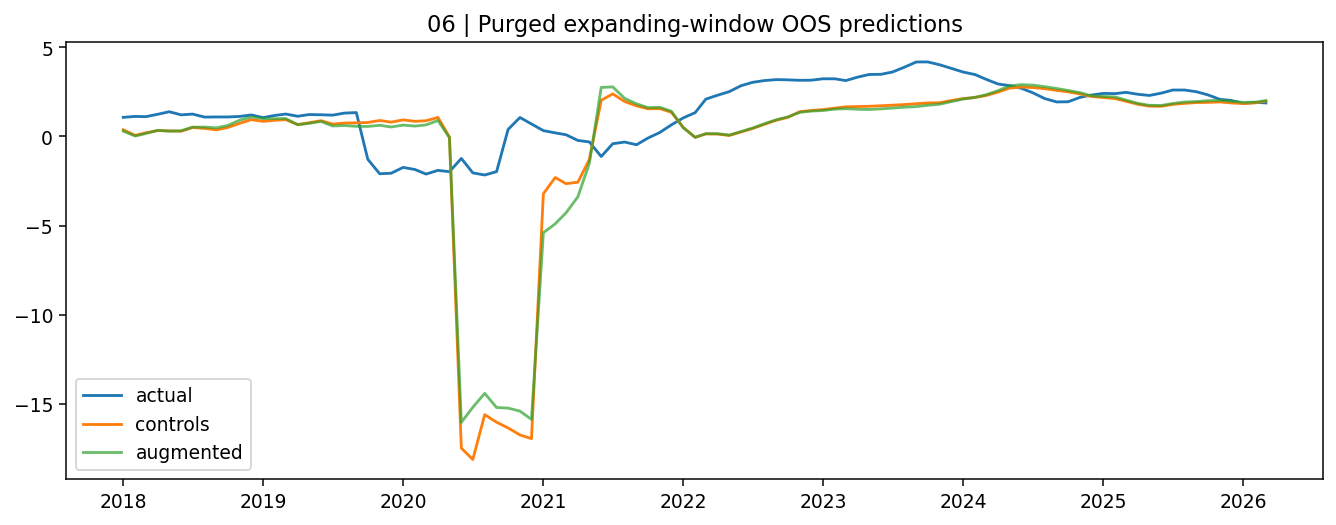

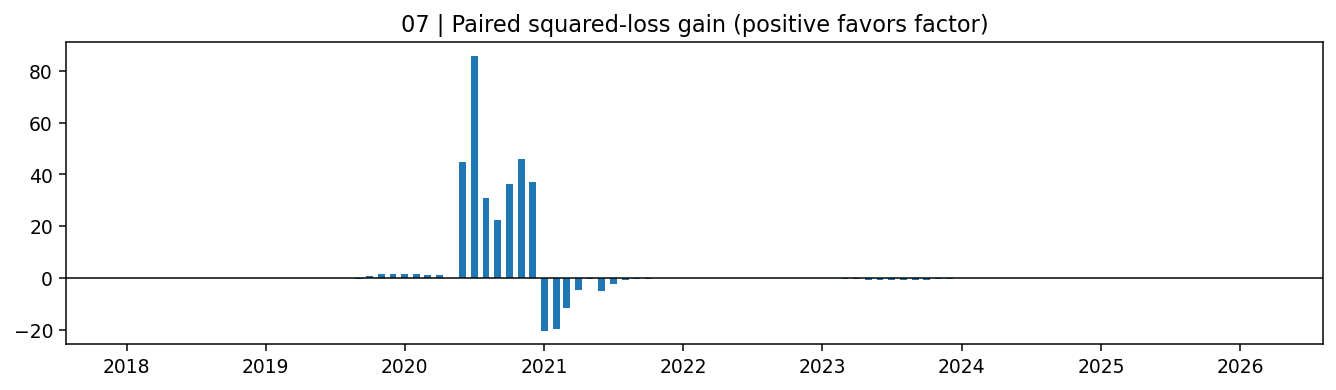

In [27]:
display(Image(filename=str(ROOT/'figures/06_oos_forecasts.png')));display(Image(filename=str(ROOT/'figures/07_paired_loss.png')))

## 10. Robustness & Placebos
**1,000 twelve-month block-order randomizations** of the factor, each with a full purged refit, give an **exploratory right-tail fraction 0.2248** for observed control-minus-full RMSE gain; because nonstationary time blocks are not exchangeable, this is **not an exact randomization p-value**. **2,000 paired moving-block bootstrap** resamples (12-month blocks) give a 95% gain interval **[-0.1782, +0.5870] log-pp**, which includes zero. **1,000 scenario weight perturbations** use `F_w=tanh([w*g_O+(1−w)*g_C−g_N]/5)` for `w∈[0.5,1]`; **100.0%** beat the weak macro controls, but **none of this validates the factor against hospital persistence**. Ablations, rolling/expanding comparison, 3/9-month horizons, 3/4-month assumed input lags, regime splits and leave-one-year-out are saved. A leave-one-company-out test is not possible without historical issuer observations.

In [28]:
pl=pd.read_csv(ROOT/'results/block_placebo_draws.csv');bt=pd.read_csv(ROOT/'results/bootstrap_draws.csv');w=pd.read_csv(ROOT/'results/exposure_weight_draws.csv');print('Actual draws:',len(pl),len(bt),len(w));assert (len(pl),len(bt),len(w))==(1000,2000,1000)

Actual draws: 1000 2000 1000


In [29]:
display(pd.DataFrame({'observed_gain':[metrics['gain_log_pp']],'block_shuffle_exploratory_tail':[metrics['placebo_right_tail_fraction']],'bootstrap_lower':[metrics['bootstrap_gain_ci95'][0]],'bootstrap_upper':[metrics['bootstrap_gain_ci95'][1]],'weight_gain_positive_fraction':[metrics['weight_positive_fraction']]}))

,observed_gain,block_shuffle_exploratory_tail,bootstrap_lower,bootstrap_upper,weight_gain_positive_fraction
0,0.275882,0.224775,-0.178151,0.587011,1.0


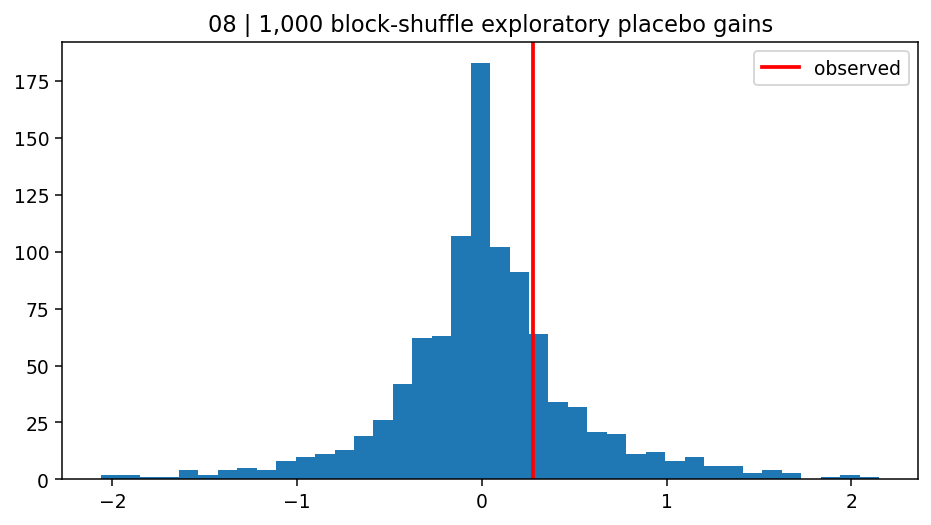

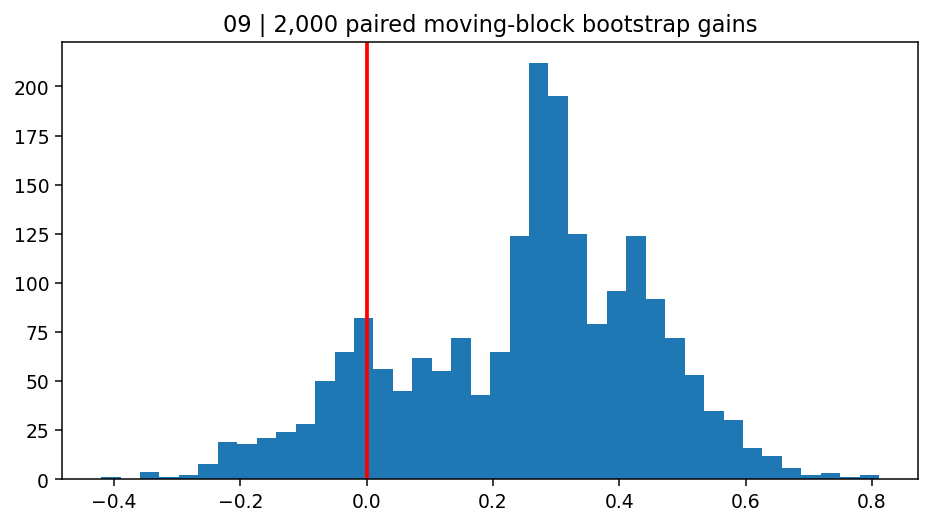

In [30]:
display(Image(filename=str(ROOT/'figures/08_placebo.png')));display(Image(filename=str(ROOT/'figures/09_bootstrap.png')))

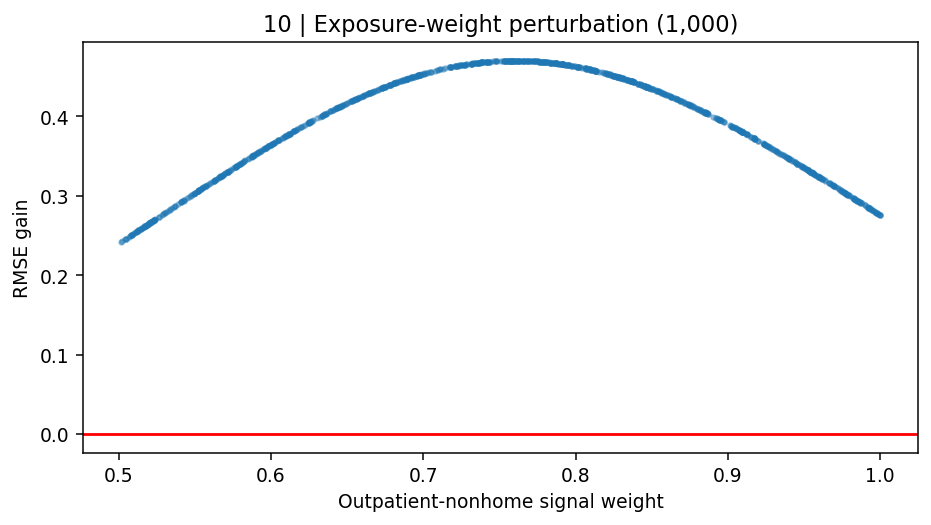

In [31]:
display(Image(filename=str(ROOT/'figures/10_weight_sensitivity.png')))

## 11. Regime Sensitivity
| Test | OOS n | Control RMSE | Full RMSE | Control − full (log-pp) |
|:--|--:|--:|--:|--:|
| horizon_3m | 102 | 2.6737 | 2.4093 | +0.2643 |
| horizon_9m | 96 | 6.8064 | 6.5516 | +0.2548 |
| lag_3m | 99 | 5.1525 | 4.7857 | +0.3668 |
| lag_4m | 99 | 5.8023 | 5.3710 | +0.4313 |
| rolling_84m | 99 | 6.9875 | 6.8399 | +0.1477 |
| pre_2020 | 24 | 1.1259 | 1.0553 | +0.0706 |
| pandemic_2020_2021 | 24 | 8.9311 | 8.3469 | +0.5842 |
| post_2021 | 51 | 1.4338 | 1.4672 | -0.0333 |
| exclude_2020_2021 | 75 | 1.3430 | 1.3491 | -0.0061 |

The control-relative benefit is concentrated in 2020–2021 (**+0.5842**), while 2022+ is **-0.0333** and excluding 2020–2021 gives **-0.0061**. Excluding **2020** alone reverses the full-sample control-relative sign (**-0.2362**), an important falsification. Alternative horizons/lags do not solve the much larger failure against persistence. Monthly overlapping YoY labels and structural breaks invalidate naive independent-observation significance tests.

In [32]:
rob=pd.read_csv(ROOT/'results/robustness.csv');loo=pd.read_csv(ROOT/'results/leave_one_year_out.csv');display(rob)

,test,n,macro_rmse,full_rmse,gain
0,horizon_3m,102,2.673654,2.409314,0.264340
1,horizon_9m,96,6.806371,6.551584,0.254787
2,lag_3m,99,5.152544,4.785703,0.366841
3,lag_4m,99,5.802289,5.370977,0.431312
4,rolling_84m,99,6.987525,6.839870,0.147654
5,pre_2020,24,1.125928,1.055346,0.070582
6,pandemic_2020_2021,24,8.931124,8.346929,0.584195
7,post_2021,51,1.433845,1.467184,-0.033339
8,exclude_2020_2021,75,1.343015,1.349144,-0.006129


In [33]:
display(loo);print('Exclude 2020 sign:',loo.loc[loo.excluded_year==2020,'gain'].iloc[0]);print('Exclude 2020-21 sign:',rob.loc[rob.test=='exclude_2020_2021','gain'].iloc[0])

,excluded_year,n,gain
0,2018,87,0.294458
1,2019,87,0.291790
2,2020,87,-0.236238
3,2021,87,0.385098
4,2022,87,0.297513
5,2023,87,0.305074
6,2024,87,0.295316
7,2025,87,0.293716
8,2026,96,0.280172


Exclude 2020 sign: -0.236238280824
Exclude 2020-21 sign: -0.00612888966406


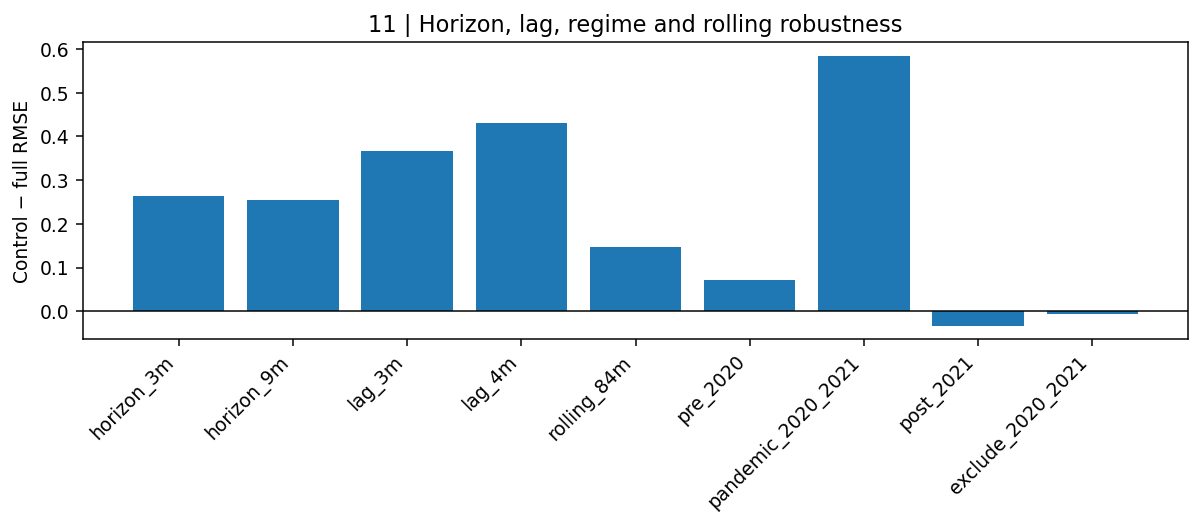

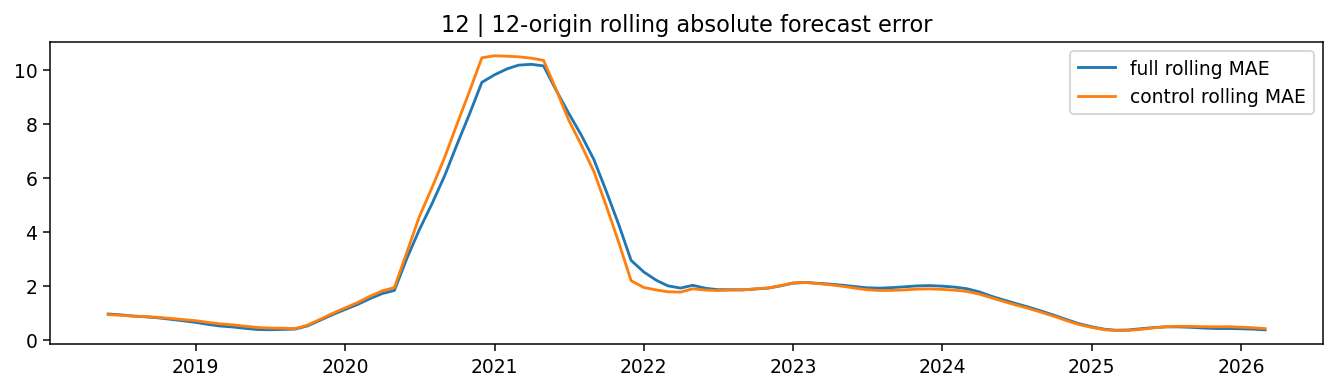

In [34]:
display(Image(filename=str(ROOT/'figures/11_robustness.png')));display(Image(filename=str(ROOT/'figures/12_rolling_errors.png')))

## 12. Bias Audit & Verdict
| Risk | Finding |
|:--|:--|
| Historical revision / lookahead | **UNRESOLVED** — latest-revised 2026-10-26 CES snapshot, no original-release ALFRED panel. |
| Release timing | Two-month input buffer and seven-month target maturity are assumptions, not verified archival timestamps. |
| Feature and fit leakage | Deterministic predeclared factor, train-only centering and target purge verified in unit tests. |
| Overlap / effective n | Monthly origins with 12-month growth labels; block-bootstrap descriptive only; n_eff≈33.8. |
| Multiple testing | This is one of many sequential industry studies; p-value familywise corrections and untouched holdout absent. |
| Sector composition | Ambulatory includes home care; subtracting counts does not identify referrals or patient volumes. |
| Firm survivorship / selection | 2025 HCA/Tenet examples chosen for description, not historical issuer universe; no firm-level OOS. |
| Security alpha / costs | No dividends, delistings, benchmark, transaction costs or capacity; **not tested**. |
| Structural break | 2020 dominates apparent improvement; post-2021 and leave-2020-out gains fail. |

**Verdict: REPRODUCED RETROSPECTIVE HOSPITAL-EMPLOYMENT MACRO FALSIFICATION — NOT PIT / NOT EQUITY ALPHA.** An apparent control-relative improvement is **economically unconvincing** because simpler hospital persistence beats the full model by a wide margin, and its timing is unstable.

In [35]:
checks=pd.DataFrame({'risk':['Revised historical CES','Target maturity','Train-only scaling','Survivorship','Total returns','Multiple testing','Overlapping target'], 'finding':['UNKNOWN PIT','7-month purge','fixed alpha, per-fold scaling','no issuer panel','not available','not adjusted','block uncertainty']});display(checks)

,risk,finding
0,Revised historical CES,UNKNOWN PIT
1,Target maturity,7-month purge
2,Train-only scaling,"fixed alpha, per-fold scaling"
3,Survivorship,no issuer panel
4,Total returns,not available
5,Multiple testing,not adjusted
6,Overlapping target,block uncertainty


In [36]:
assert metrics['historical_publication_vintages'].startswith('UNKNOWN');assert metrics['security_total_returns']=='NOT AVAILABLE';assert metrics['bootstrap_gain_ci95'][0]<0<metrics['bootstrap_gain_ci95'][1];print('Uncertainty and bias verdict: no investable alpha')

Uncertainty and bias verdict: no investable alpha


## 13. Reproduction
Python 3.10+ from this directory:

```bash
pip install -r requirements.txt
OPENBLAS_NUM_THREADS=1 python run_analysis.py
PYTHONPATH=. OPENBLAS_NUM_THREADS=1 pytest -q tests
jupyter nbconvert --to notebook --execute research.ipynb --output /tmp/hospital-reexecuted.ipynb
```

From repository root: `python scripts/validate_studies.py`. The frozen source hash is asserted at runtime; `results/metrics.json`, complete placebo/bootstrap/weight draws, `results/walk_forward_oos.csv`, 12 computed figures and the executed notebook are reproducible offline. Local run logs in `logs/` record actual execution; repository CI's structural gate does **not** establish numerical reproduction or historical PIT.

In [37]:
files=sorted([str(x.relative_to(ROOT)) for x in (ROOT/'figures').glob('*.png')]);print('Computed figure count:',len(files));print('\n'.join(files))

Computed figure count: 12
figures/01_sector_levels.png
figures/02_growth_rates.png
figures/03_factor_target.png
figures/04_scatter.png
figures/05_scorecard.png
figures/06_oos_forecasts.png
figures/07_paired_loss.png
figures/08_placebo.png
figures/09_bootstrap.png
figures/10_weight_sensitivity.png
figures/11_robustness.png
figures/12_rolling_errors.png


In [38]:
print('Data SHA:',hashlib.sha256(ra.RAW.read_bytes()).hexdigest());print('Analysis log:',(ROOT/'logs'/'analysis.log').exists());print('Test log:',(ROOT/'logs'/'pytest.log').exists())

Data SHA: f1d5a8ff28a55f2d1798cbdb9cac239d46db6c006b0a9e1801abae1b3b1665f6
Analysis log: True
Test log: True


## 14. Next-Stage Protocol
(1) Download **ALFRED CES first-release vintages** and actual release calendars, archive checksums and rebuild a formation-date availability panel. (2) Obtain **CMS hospital admissions, utilization and claims** as independent hospital-demand outcomes with release dates; avoid treating hiring as patient volume. (3) Add dated issuer-specific hospital/ASC segment revenue and earnings for a **predeclared complete historical issuer universe** with filing-date lags; test issuer-level sales/EPS against naive and sector baselines. (4) Only after credible fundamental lead, acquire delisting-inclusive **total returns**, market/healthcare benchmark returns and execution costs; evaluate sector-neutral portfolio spreads, capacity and realistic trading dates. (5) Freeze hypotheses before a new holdout and correct for the broad family of industry studies and scenario searches.

In [39]:
print('Next-stage requirements: ALFRED first-release vintages, CMS utilization, dated issuer filings, delisting-inclusive total returns, costs, multiple-test holdout.')

Next-stage requirements: ALFRED first-release vintages, CMS utilization, dated issuer filings, delisting-inclusive total returns, costs, multiple-test holdout.


In [40]:
print('Do not interpret employment levels as corporate revenue, hospital admissions or tradable return signals.')

Do not interpret employment levels as corporate revenue, hospital admissions or tradable return signals.


## 15. Sources & Artifacts
**Original A-grade series:** [BLS hospitals](https://fred.stlouisfed.org/series/CES6562200001), [ambulatory](https://fred.stlouisfed.org/series/CES6562100001), [home health](https://fred.stlouisfed.org/series/CES6562160001), [nursing](https://fred.stlouisfed.org/series/CES6562300001), [national payroll](https://fred.stlouisfed.org/series/PAYEMS). **Issuer filings:** [HCA 2025 SEC 10-K, filed 2026-02-10](https://www.sec.gov/Archives/edgar/data/860730/000119312526044769/hca-20251231.htm) and [Tenet 2025 SEC 10-K, filed 2026-02-17](https://www.sec.gov/Archives/edgar/data/70318/000007031826000012/thc-20251231.htm). **Inherited snapshot provenance:** [prior healthcare study frozen CES CSV](https://github.com/HyeonbinJung/Signals-to-Alpha/blob/main/Home-Care-Pressure-to-Alpha-U.S.-Healthcare-Services/data/fred_ces_2010_2026_snapshot.csv). The BLS/FRED series were last released 2026-10-02 in this snapshot; original observation-specific timestamps **UNKNOWN**. All URLs, units, revisions, grades and roles are in `data/source_register.csv`. Raw/derived data and dated issuer maps: `data/`; models: `run_analysis.py`; real scorecards/distributions: `results/`; 12 computed diagnostic charts: `figures/`; execution and tests: `logs/` and `tests/`.

In [41]:
display(source[['source_id','grade','source_url','source_release_date','original_observation_release_timestamps']])

,source_id,grade,source_url,source_release_date,original_observation_release_timestamps
0,CES6562200001,A,https://fred.stlouisfed.org/series/CES6562200001,2026-10-02,UNKNOWN
1,CES6562100001,A,https://fred.stlouisfed.org/series/CES6562100001,2026-10-02,UNKNOWN
2,CES6562160001,A,https://fred.stlouisfed.org/series/CES6562160001,2026-10-02,UNKNOWN
3,CES6562300001,A,https://fred.stlouisfed.org/series/CES6562300001,2026-10-02,UNKNOWN
4,PAYEMS,A,https://fred.stlouisfed.org/series/PAYEMS,2026-10-02,UNKNOWN
5,HCA_2025_10K,A,https://www.sec.gov/Archives/edgar/data/860730...,2026-02-10,2026-02-10
6,THC_2025_10K,A,https://www.sec.gov/Archives/edgar/data/70318/...,2026-02-17,2026-02-17
7,SNAPSHOT_INHERITANCE,B,https://github.com/HyeonbinJung/Signals-to-Alp...,2026-10-26,UNKNOWN
8,WEIGHT_PRIOR,C,NOT EXTERNAL,2026-10-28,not applicable


In [42]:
print('All artifacts saved under data/, results/, figures/, tests/, logs/; 2026 revised snapshot is NOT original-release PIT.')

All artifacts saved under data/, results/, figures/, tests/, logs/; 2026 revised snapshot is NOT original-release PIT.
